# Every run under one evaluation type: sparsity, rotation, compass, ...

Runtime -> Change runtime type -> **GPU** (T4 is enough). Set cell 1, then **Runtime -> Run all**.

For every finished run on Drive (NDT-Transformer `ndt`, BEVPlace++ `bev`, own NDT network `myndt`, and the official
BEVPlace++ checkpoint), or only the runs in `ONLY_RUNS`, this runs the evaluation type `EVAL_TYPE` (`src/lpr/evals.py`)
on its last checkpoint, without retraining:

- **`sparsity`** (default): 64 beams (the run's own variant); **`both`**: map and queries from the 32 / 16-beam variant
  (a cheaper LiDAR everywhere); **`query`**: map from 64 beams, queries from 32 / 16 beams (a cheaper LiDAR in a good map).
  The sparse variants were built on Azure; this notebook copies them from the blob container (SAS URL in Colab
  Secrets as `AZURE_SAS`, read + list is enough).
- **`rotation`**: the map as recorded, every query rotated about z by its own angle from U[-alpha, alpha],
  alpha in {0, 5, 15, 45, 90, 180} degrees (the rotation curve).
- **`compass`**, **`seqs_heading`**: as in notebooks 01 / 02 / 04, for many runs at once.

Optional: section 7 (density check, `DENSITY_CHECK`) and section 8 (the official BEVPlace++ checkpoint with the 08 split of
the paper, `SPLIT08_CHECK`). Results: `<run>/eval/<type>/<checkpoint>/`, and the table at the end
(`MyDrive/lpr/<type>_all_runs.csv`). A complete evaluation is not repeated, so Run all again after a disconnect.


## 1. Settings

In [9]:
REPO_URL = "https://github.com/dov85/lidar-place-recognition"
DRIVE = "/content/drive/MyDrive/lpr"
KITTI = "/content/kitti"                 # poses only
METHODS = ["ndt", "myndt", "bev"]        # which kinds of runs
STATUS = ["finished"]                    # runs with this status in their config.json
INCLUDE_RUNS = []                        # extra run folders, whatever their status, e.g. ["2026-10-19_de5611"]
EXCLUDE_RUNS = []                        # run folders to skip
EVAL_CKPT = "last"                       # "last" or a checkpoint file name, the same for every run
OFFICIAL_BEV = True                      # also the authors' BEVPlace++ checkpoint (runs/bev/official_<variant>)
EVAL_TYPE = "rotation"
ONLY_RUNS = ["2026-10-06_cov_transform_5c90e2", "2026-10-07_f60015", "2026-10-12_e39427",
             "2026-10-19_283ebc", "2026-10-20_3fe7a5", "2026-10-08_without_Rein_b14094",
             "2026-10-08_without_Rein_with_rot_216fa5", "2026-10-05_baseline_4ac7d1",
             "official_2026-10-05_baseline_7711ab"]                       # if not empty: only these run folders (any status), e.g. ["2026-10-20_3fe7a5"]
PARAMS = {}                              # overrides of the type's parameters, e.g. {"beams": [16], "modes": ["both"]}
DENSITY_CHECK = False                    # section 7: density check of CHECK_RUNS (needs the 16-beam variants)
SPLIT08_CHECK = True                   # section 8: official BEVPlace++ checkpoint on 08 with the paper's split (3000)

## 2. Drive, GPU, code, poses

In [10]:
from google.colab import drive, userdata
drive.mount('/content/drive')
import os, sys, json, glob, subprocess, importlib
!nvidia-smi --query-gpu=name,memory.total --format=csv
url = REPO_URL
try:  # private repo: store a token in Colab Secrets as GITHUB_TOKEN
    url = REPO_URL.replace("https://", f"https://{userdata.get('GITHUB_TOKEN')}@")
except Exception:
    pass
if not os.path.exists("/content/lpr"):
    subprocess.run(["git", "clone", "-q", url, "/content/lpr"], check=True)
else:
    subprocess.run(["git", "-C", "/content/lpr", "pull", "-q"], check=True)
%cd /content/lpr
!git log --oneline -1
!bash scripts/setup_third_party.sh
!pip install -q -r requirements.txt
sys.path.insert(0, "/content/lpr/src")
import lpr.experiments as ex, lpr.evals as ev
importlib.reload(ex); importlib.reload(ev)
missing_poses = [s for s in ev.ALL_SEQS if not os.path.exists(f"{KITTI}/poses/{s}.txt")]
if missing_poses:
    !python scripts/download_kitti.py --out {KITTI} --seqs {" ".join(missing_poses)} --poses_only
SP = ev.full_eval_params(EVAL_TYPE, PARAMS)
print(EVAL_TYPE, "parameters:", SP)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
name, memory.total [MiB]
Tesla T4, 15360 MiB
/content/lpr
c76d2bd (HEAD -> main, origin/main, origin/HEAD) Rotation curve (evaluation type rotation), notebook 05 for any evaluation type (+ density check / paper's 08 split switches), --split for eval_bev_kitti, benchmark.py + notebook 07 (resources, method figure), report_figures.py, README: reproducing the report, requirements
third_party/NDT-Transformer @ 51f90df
third_party/BEVPlace2 @ 2d0636d5
rotation parameters: {'seqs': ['00', '02', '05', '06', '08'], 'alpha_deg': [0, 5, 15, 45, 90, 180], 'seed': 0}


## 3. The runs

In [11]:
import pandas as pd
OFFICIAL_CKPT = "/content/lpr/third_party/BEVPlace2/runs/Aug08_10-17-29/model_best.pth.tar"
DATA = {"ndt": "ndt", "myndt": "ndt", "bev": "bev"}     # whose variants a method uses
runs = []
for m in METHODS:
    for cfg_path in sorted(glob.glob(f"{DRIVE}/runs/{m}/*/config.json")):
        run_dir = os.path.dirname(cfg_path)
        name = os.path.basename(run_dir)
        cfg = json.load(open(cfg_path))
        official = m == "bev" and name.startswith("official_")
        if name in EXCLUDE_RUNS or (official and not OFFICIAL_BEV):
            continue
        if ONLY_RUNS and name not in ONLY_RUNS:
            continue
        if not ONLY_RUNS and cfg.get("status") not in STATUS and name not in INCLUDE_RUNS and not official:
            continue
        if official:
            ckpt = OFFICIAL_CKPT
        elif glob.glob(f"{run_dir}/epoch_*.pth"):
            ckpt = EVAL_CKPT
        else:
            continue
        variant = cfg.get(f"{DATA[m]}_variant")
        if not variant:
            print("no variant in", cfg_path, "(skipped)")
            continue
        runs.append(dict(method=m, run=name, run_dir=run_dir, ckpt=ckpt, variant=variant,
                         data_dir=f"/content/{DATA[m]}/{variant}", status=cfg.get("status")))
RUNS = pd.DataFrame(runs)
print(len(RUNS), "runs")
display(RUNS[["method", "run", "status", "variant"]])

9 runs


,method,run,status,variant
0,ndt,2026-10-06_cov_transform_5c90e2,finished,2026-10-04_baseline_717e81
1,ndt,2026-10-07_f60015,finished,2026-10-04_baseline_717e81
2,ndt,2026-10-12_e39427,finished,2026-10-04_baseline_717e81
3,myndt,2026-10-19_283ebc,finished,2026-10-04_baseline_717e81
4,myndt,2026-10-20_3fe7a5,finished,2026-10-04_baseline_717e81
5,bev,2026-10-05_baseline_4ac7d1,running,2026-10-05_baseline_7711ab
6,bev,2026-10-08_without_Rein_b14094,finished,2026-10-05_baseline_7711ab
7,bev,2026-10-08_without_Rein_with_rot_216fa5,finished,2026-10-05_baseline_7711ab
8,bev,official_2026-10-05_baseline_7711ab,finished,2026-10-05_baseline_7711ab


## 4. Data: the runs' 64-beam variants and their 32 / 16-beam variants
Every sequence of every variant is copied to this machine (`/content/ndt/<variant>/`, `/content/bev/<variant>/`);
what is not on Drive yet is copied from the blob container first.

In [12]:
SAS = userdata.get("AZURE_SAS")
for (dm, variant), _ in RUNS.groupby([RUNS.method.map(DATA), "variant"]):
    vdir, local = f"{DRIVE}/{dm}/{variant}", f"/content/{dm}/{variant}"
    tar = lambda s: f"{vdir}/{ex.archive_name(dm, s)}"
    missing = [s for s in SP["seqs"] if not os.path.exists(tar(s))]
    if missing:
        res = subprocess.run(["python", "scripts/fetch_from_azure.py", "--sas_url", SAS, "--method", dm,
                              "--variant", variant, "--seqs", *missing, "--drive", DRIVE],
                             capture_output=True, text=True, cwd="/content/lpr")
        print(res.stdout, res.stderr[-2000:])
    ext = "000000.png" if dm == "bev" else "000000.bin"
    for s in SP["seqs"]:
        if os.path.exists(tar(s)) and not os.path.exists(f"{local}/{s}/{ext}"):
            os.makedirs(local, exist_ok=True)
            subprocess.run(["tar", "-xf", tar(s), "-C", local], check=True)
    if not os.path.exists(f"{local}/config.json") and os.path.exists(f"{vdir}/config.json"):
        subprocess.run(["cp", f"{vdir}/config.json", f"{local}/config.json"], check=True)
    print(f"{dm} {variant}: on this machine for", [s for s in SP["seqs"] if os.path.exists(f"{local}/{s}/{ext}")])
    if EVAL_TYPE != "sparsity" and not DENSITY_CHECK:
        continue                         # the 32 / 16-beam variants are only needed for these
    res = subprocess.run(["python", "scripts/fetch_sparse.py", "--method", dm, "--variant", variant,
                          "--drive", DRIVE, "--data_root", f"/content/{dm}", "--sas_url", SAS,
                          "--beams", *map(str, SP.get("beams", [32, 16])), "--seqs", *SP["seqs"]],
                         capture_output=True, text=True, cwd="/content/lpr")
    print(res.stdout, res.stderr[-2000:])

bev 2026-10-05_baseline_7711ab: on this machine for ['00', '02', '05', '06', '08']
ndt 2026-10-04_baseline_717e81: on this machine for ['00', '02', '05', '06', '08']


## 5. Evaluations
One `EVAL_TYPE` evaluation per run. Already complete ones are skipped; a disconnected one continues with the
sequences that are missing.

In [13]:
import time
for r in RUNS.itertuples():
    t0 = time.time()
    res = subprocess.run(["python", "scripts/evaluate.py", "--method", r.method, "--run_dir", r.run_dir,
                          "--ckpt", r.ckpt, "--eval_type", EVAL_TYPE, "--data_dir", r.data_dir,
                          "--kitti_root", KITTI, "--params", json.dumps(PARAMS)],
                         capture_output=True, text=True, cwd="/content/lpr")
    out = res.stdout if res.returncode == 0 else res.stdout[-2000:] + res.stderr[-3000:]
    print(f"===== {r.method} {r.run} ({(time.time() - t0) / 60:.1f} min)")
    print("\n".join(out.splitlines()[-14:]))

===== ndt 2026-10-06_cov_transform_5c90e2 (0.0 min)
        45  02 33.55 36.18 48.03      304                      0.5                  0.2          84.2            39.8                  0.7                    0.0               15.1                  0.0
        45  05 58.84 68.68 72.71      447                      0.8                  0.2          93.3            61.6                  6.7                   20.0                0.0                  NaN
        45  06 65.56 77.04 77.41      270                      0.5                  0.2         100.0            65.6                  0.0                    NaN                0.0                  NaN
        45  08  2.95  6.23 10.49      305                    177.2                176.1           0.0             NaN                  6.6                    5.0               93.4                  2.8
        90  00 30.21 34.90 44.72      682                      1.0                  0.3          97.8            30.4                  1.5  

## 6. Tables and plots: Recall@1 (%) per run

-> /content/drive/MyDrive/lpr/rotation_all_runs.csv
Recall@1 on 08 per alpha_deg


alpha_deg                                       0.0    5.0    15.0   45.0   \
method run                                                                   
bev    2026-10-05_baseline_4ac7d1               91.15  92.46  92.46  90.82   
       2026-10-08_without_Rein_b14094            1.31   1.31   3.28   3.93   
       2026-10-08_without_Rein_with_rot_216fa5  91.15  88.20  88.52  89.84   
       official_2026-10-05_baseline_7711ab      94.10  95.08  95.08  94.75   
myndt  2026-10-19_283ebc                        65.90  65.90  67.21  66.89   
       2026-10-20_3fe7a5                        82.30  82.62  80.00  77.70   
ndt    2026-10-06_cov_transform_5c90e2           5.25   3.93   4.59   2.95   
       2026-10-07_f60015                        55.74  56.39  55.74  55.74   
       2026-10-12_e39427                        51.48  51.80  51.15  52.13   

alpha_deg                                       90.0   180.0  
method run                                                    
bev    2026-10-05_baseline_4ac7d1               93.11  91.48  
       2026-10-08_without_Rein_b14094            3.61  20.66  
       2026-10-08_without_Rein_with_rot_216fa5  90.16  90.49  
       official_2026-10-05_baseline_7711ab      94.43  95.08  
myndt  2026-10-19_283ebc                        65.90  66.56  
       2026-10-20_3fe7a5                        79.02  80.98  
ndt    2026-10-06_cov_transform_5c90e2           3.93  14.43  
       2026-10-07_f60015                        55.74  62.62  
       2026-10-12_e39427                        51.80  57.70

Mean Recall@1 over the sequences per alpha_deg


alpha_deg                                       0.0    5.0    15.0   45.0   \
method run                                                                   
bev    2026-10-05_baseline_4ac7d1               97.75  98.06  98.02  97.69   
       2026-10-08_without_Rein_b14094           73.35  73.13  73.09  54.66   
       2026-10-08_without_Rein_with_rot_216fa5  97.49  96.82  97.08  97.03   
       official_2026-10-05_baseline_7711ab      98.13  98.35  98.13  97.95   
myndt  2026-10-19_283ebc                        89.61  89.50  89.60  88.92   
       2026-10-20_3fe7a5                        93.53  93.63  92.41  92.01   
ndt    2026-10-06_cov_transform_5c90e2          74.02  73.67  71.15  42.88   
       2026-10-07_f60015                        86.16  86.22  85.84  85.12   
       2026-10-12_e39427                        84.86  84.77  84.67  82.27   

alpha_deg                                       90.0   180.0  
method run                                                    
bev    2026-10-05_baseline_4ac7d1               98.13  97.69  
       2026-10-08_without_Rein_b14094           30.96  19.01  
       2026-10-08_without_Rein_with_rot_216fa5  97.05  96.97  
       official_2026-10-05_baseline_7711ab      98.07  98.00  
myndt  2026-10-19_283ebc                        87.63  85.21  
       2026-10-20_3fe7a5                        92.45  92.88  
ndt    2026-10-06_cov_transform_5c90e2          25.09  15.33  
       2026-10-07_f60015                        81.90  80.68  
       2026-10-12_e39427                        80.71  77.85

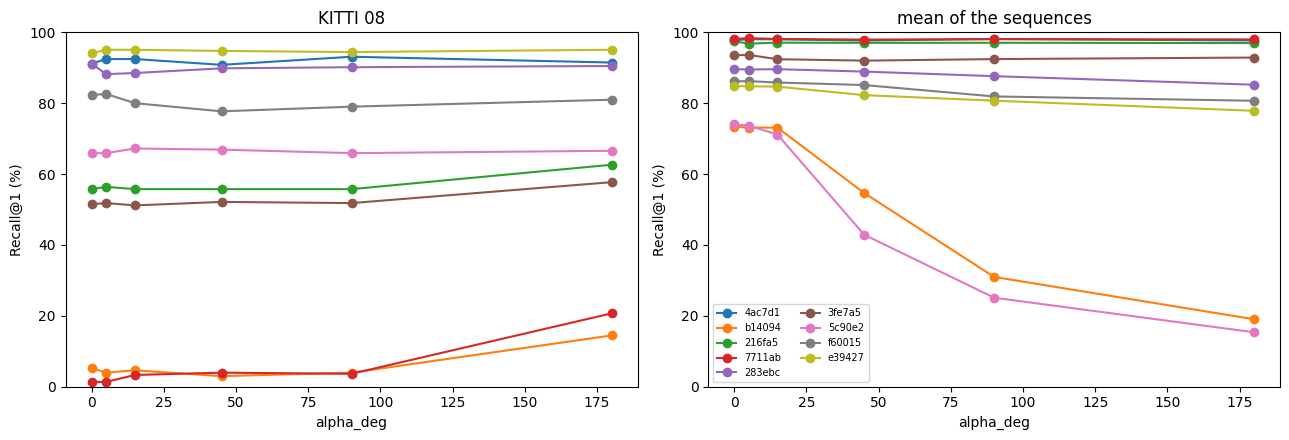

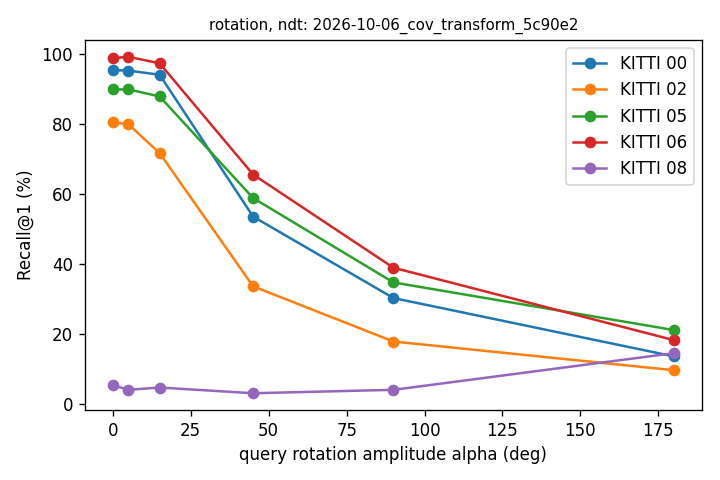

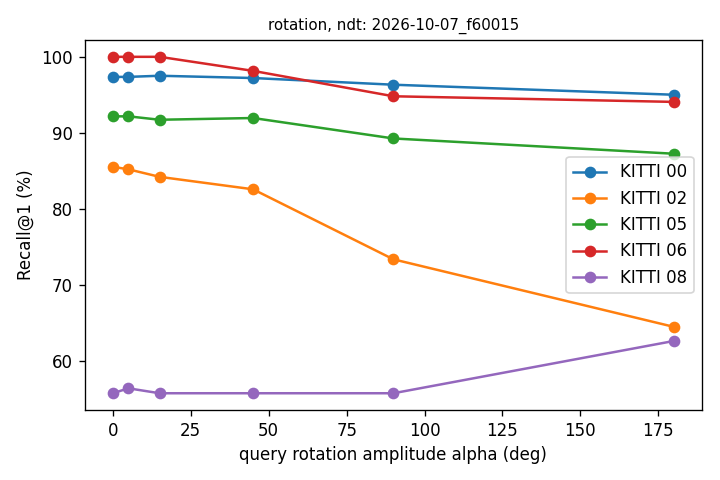

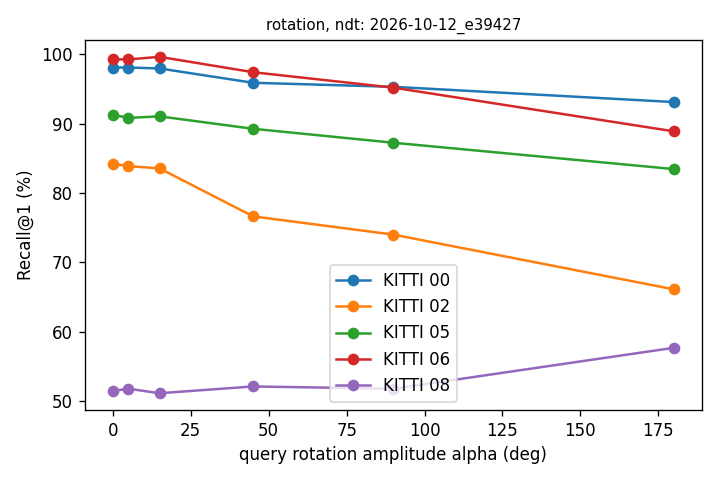

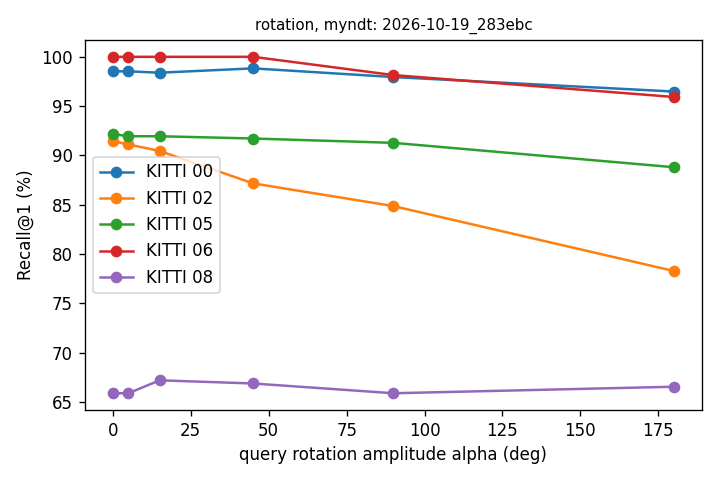

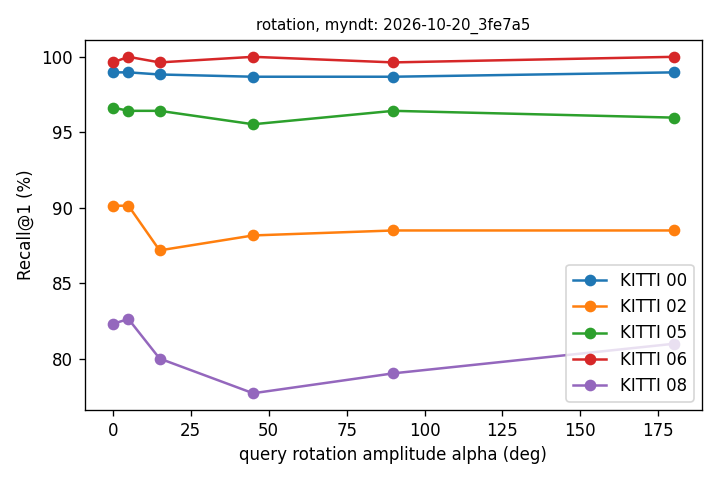

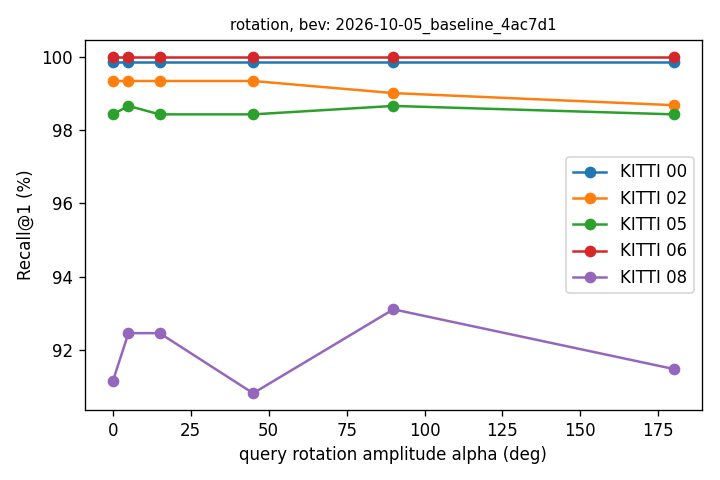

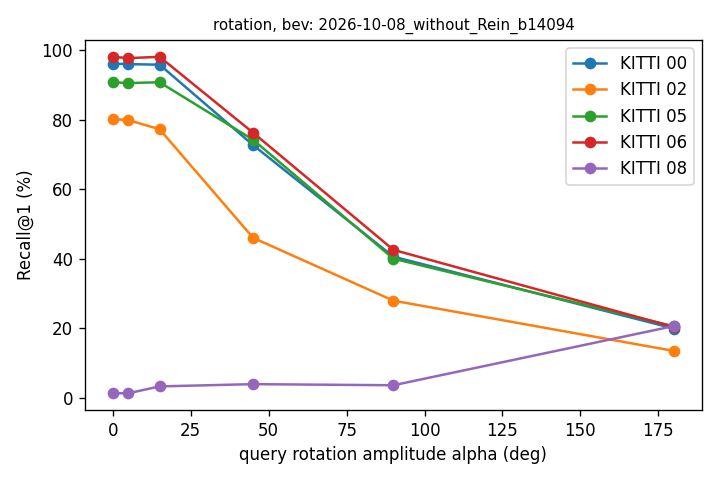

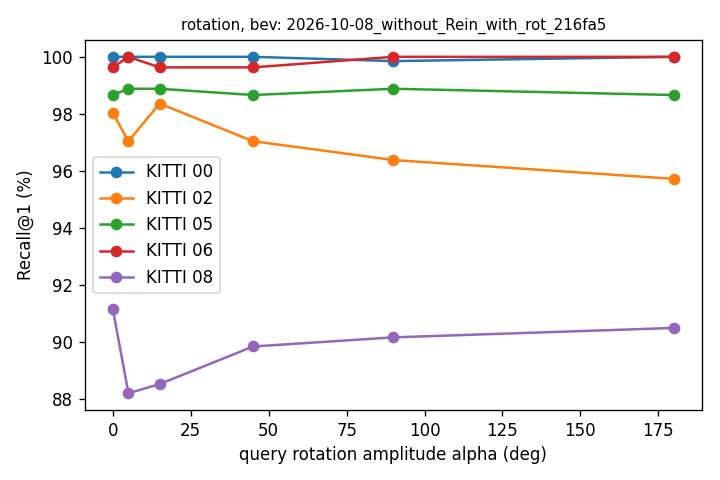

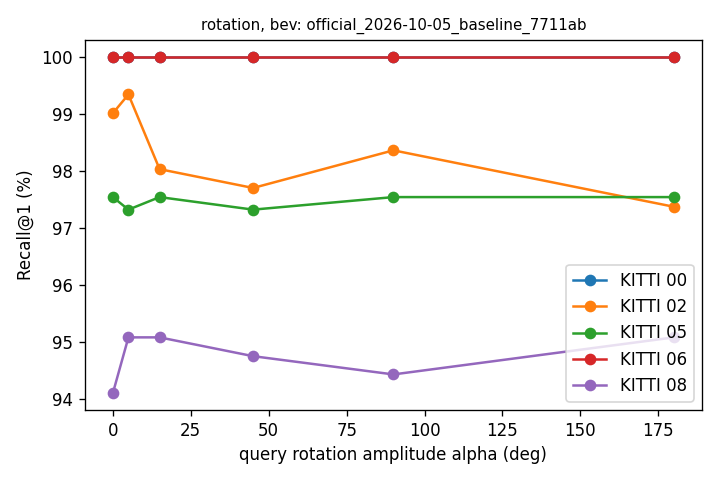

In [14]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
!python scripts/summarize_runs.py --drive {DRIVE} > /dev/null
e = pd.read_csv(f"{DRIVE}/evals_summary.csv", dtype={"seq": str, "run": str, "checkpoint": str})
sp = e[(e.eval_type == EVAL_TYPE) & e.run.isin(RUNS.run)].copy()
sp.to_csv(f"{DRIVE}/{EVAL_TYPE}_all_runs.csv", index=False)
print("->", f"{DRIVE}/{EVAL_TYPE}_all_runs.csv")
if EVAL_TYPE == "sparsity":
    sp["beams"] = sp["beams"].astype(int)
    for mode in SP["modes"]:
        t = sp[sp["mode"] == mode].pivot_table(index=["method", "run", "checkpoint"], columns=["beams", "seq"],
                                               values="R@1").sort_index(axis=1, level=0, ascending=False)
        print({"both": "MODE both: map and queries sparse", "query": "MODE query: map 64 beams, queries sparse"}[mode])
        display(t.round(2))
    print("Mean Recall@1 over the sequences")
    display(sp.pivot_table(index=["method", "run"], columns=["mode", "beams"], values="R@1", aggfunc="mean")
              .sort_index(axis=1, level=[0, 1], ascending=[True, False]).round(2))
elif EVAL_TYPE in ("rotation", "compass"):
    key = {"rotation": "alpha_deg", "compass": "sigma_deg"}[EVAL_TYPE]
    for seq in ["08"]:
        print(f"Recall@1 on {seq} per {key}")
        display(sp[sp.seq == seq].pivot_table(index=["method", "run"], columns=key, values="R@1").round(2))
    print(f"Mean Recall@1 over the sequences per {key}")
    mean = sp.pivot_table(index=["method", "run"], columns=key, values="R@1", aggfunc="mean").round(2)
    display(mean)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, (title, t) in zip(axes, [("KITTI 08", sp[sp.seq == "08"].pivot_table(index="run", columns=key, values="R@1")),
                                     ("mean of the sequences", mean.droplevel(0))]):
        for run, row in t.iterrows():
            ax.plot(row.index, row.values, "o-", label=run[-6:])
        ax.set_xlabel(key); ax.set_ylabel("Recall@1 (%)"); ax.set_title(title); ax.set_ylim(0, 100)
    axes[1].legend(fontsize=7, ncol=2)
    fig.tight_layout(); fig.savefig(f"{DRIVE}/{EVAL_TYPE}_all_runs.png", dpi=150); plt.show()
else:
    display(sp.pivot_table(index=["method", "run"], columns="seq", values="R@1").round(2))
for r in RUNS.itertuples():
    png = glob.glob(f"{r.run_dir}/eval/{EVAL_TYPE}/*/*.png")
    if png:
        display(Image(sorted(png)[-1]))

## 7. Density check: why some runs fail with a 64-beam map and 16-beam queries
`scripts/density_check.py`: descriptors of the same 400 scans (about 10 m apart) with 64 beams and with 32 / 16 beams.
- `self_top1`: % of sparse scans whose nearest 64-beam descriptor is the same scan (100 = density does not matter);
- `ratio`: distance scan(64) - same scan(sparse), divided by the typical distance between different scans (< 1 is good);
- `spread`: spread of the sparse descriptors relative to the 64-beam ones (well below 1 = they collapse together);
- `shift`: how far the mean sparse descriptor moved, in the same unit; `hub_share`: % of queries that all pick the same scan;
- `norm_64` / `norm_sparse`: descriptor norms (1 for L2-normalised heads).
Saved per run in `<run>/eval/density_check_<seq>.json`; not recomputed once there. Runs only with `DENSITY_CHECK = True`
(the runs must also be in `RUNS`: with `ONLY_RUNS`, list them there too).

In [15]:
CHECK_RUNS = ["2026-10-08_without_Rein_with_rot_216fa5", "2026-10-08_without_Rein_b14094",
              "official_2026-10-05_baseline_7711ab", "2026-10-07_f60015", "2026-10-04_baseline_4ed638",
              "2026-10-20_065c48", "2026-10-20_3fe7a5",
              "2026-10-25_without_Rein_26962e", "2026-10-25_dbc4f4"]   # the last two: beam_aug
CHECK_SEQS = ["08", "00"]
if not DENSITY_CHECK:
    print("skipped (DENSITY_CHECK = False)")
else:
    rows = []
    for r in RUNS[RUNS.run.isin(CHECK_RUNS)].itertuples():
        for s in CHECK_SEQS:
            out = f"{r.run_dir}/eval/density_check_{s}.json"
            if not os.path.exists(out):
                os.makedirs(os.path.dirname(out), exist_ok=True)
                res = subprocess.run(["python", "scripts/density_check.py", "--method", r.method, "--run_dir", r.run_dir,
                                      "--ckpt", r.ckpt, "--data_dir", r.data_dir, "--kitti_root", KITTI, "--seq", s,
                                      "--out", out], capture_output=True, text=True, cwd="/content/lpr")
                if res.returncode:
                    print(r.run, s, res.stdout[-500:], res.stderr[-1500:])
                    continue
            rows += json.load(open(out))
    DC = pd.DataFrame(rows)
    if len(DC):
        DC.to_csv(f"{DRIVE}/density_check.csv", index=False)
        display(DC.drop(columns=["checkpoint", "n"]).set_index(["seq", "beams", "method", "run"]).sort_index())

skipped (DENSITY_CHECK = False)


## 8. The official BEVPlace++ checkpoint with the 08 split of the paper (`SPLIT08_CHECK`)
The official code splits 08 at frame 1000 (database 0-999, queries from 1200), Table II of the BEVPlace++ paper at 3000
(database 0-2999, queries 3200-). Does the paper's split explain 94.1% here against 99.1% in the paper?
Needs the official run in `RUNS` (`OFFICIAL_BEV = True`, and in `ONLY_RUNS` if that is used).

In [16]:
if not SPLIT08_CHECK:
    print("skipped (SPLIT08_CHECK = False)")
else:
    off = RUNS[RUNS.run.str.startswith("official_")].iloc[0]
    rows = []
    for split in [1000, 3000]:
        out = f"{off.run_dir}/eval/split08/split_{split}.json"
        if not os.path.exists(out):
            os.makedirs(os.path.dirname(out), exist_ok=True)
            res = subprocess.run(["python", "scripts/eval_bev_kitti.py", "--ckpt", off.ckpt, "--bev_dir", off.data_dir,
                                  "--kitti_root", KITTI, "--seq", "08", "--split", str(split), "--out", out],
                                 capture_output=True, text=True, cwd="/content/lpr")
            if res.returncode:
                print(res.stdout[-1000:], res.stderr[-2000:])
                continue
        r = json.load(open(out))
        rows.append({"split": split, **{k: r[k] for k in r if k.startswith("R@") or k in ("n_queries", "n_queries_with_positive")}})
    display(pd.DataFrame(rows))

,split,R@1,R@5,R@10,R@1%,n_queries,n_queries_with_positive
0,1000,94.098361,98.688525,99.672131,99.672131,2871,305
1,3000,90.000000,90.000000,90.000000,100.000000,871,10
